# Dumbbell Chart (connected dot plot)

**Family:** Magnitude &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Magnitude:* Compare sizes, relative or absolute (usually counts rather than rates).

## Design purpose

Two dots per category joined by a line: before and after, or group A and group B. The line's length shows the gap and its direction shows which value is larger. It is far cleaner than paired bars.

## When to use

- Compare two values per category (2015 vs. 2025, men vs. women, target vs. actual)
- The size of the gap is the story
- Values don't start at zero, so bars would be misleading

## Avoid when

- There are more than two values per category (use a dot plot with several markers)

## Alternatives

- Grouped bar chart
- Slope chart
- Arrow chart

## Design tips

- Sort by the gap or by one end; label the two colors directly once at the top

## Example

Life expectancy at birth in 2000 vs. 2022 for ten countries (approximate values).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
pio.templates["vizlib"] = go.layout.Template(layout=dict(
    colorway=PALETTE, font=dict(family="Helvetica, Arial, sans-serif", size=13, color="#0b0b0b"),
    paper_bgcolor="#fcfcfb", plot_bgcolor="#fcfcfb", title=dict(x=0.02, xanchor="left"),
    xaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
    yaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
))
pio.templates.default = "plotly_white+vizlib"
pio.renderers.default = "plotly_mimetype+notebook_connected"

### Data

In [2]:
df = pd.DataFrame({
    "country": ["Japan", "Taiwan", "Germany", "USA", "China", "Brazil",
                "India", "Russia", "South Africa", "Nigeria"],
    "y2000": [81.2, 76.5, 78.0, 76.8, 71.4, 70.1, 62.7, 65.3, 55.9, 46.3],
    "y2022": [84.0, 79.8, 80.7, 77.5, 78.6, 73.4, 67.7, 70.1, 61.5, 53.6],
})
start, end = "y2000", "y2022"
title = "Life expectancy rose everywhere, but gaps remain"
df["gain"] = df[end] - df[start]
df = df.sort_values(end).reset_index(drop=True)
df

,country,y2000,y2022,gain
0,Nigeria,46.3,53.6,7.3
1,South Africa,55.9,61.5,5.6
2,India,62.7,67.7,5.0
3,Russia,65.3,70.1,4.8
4,Brazil,70.1,73.4,3.3
5,USA,76.8,77.5,0.7
6,China,71.4,78.6,7.2
7,Taiwan,76.5,79.8,3.3
8,Germany,78.0,80.7,2.7
9,Japan,81.2,84.0,2.8


### Plot

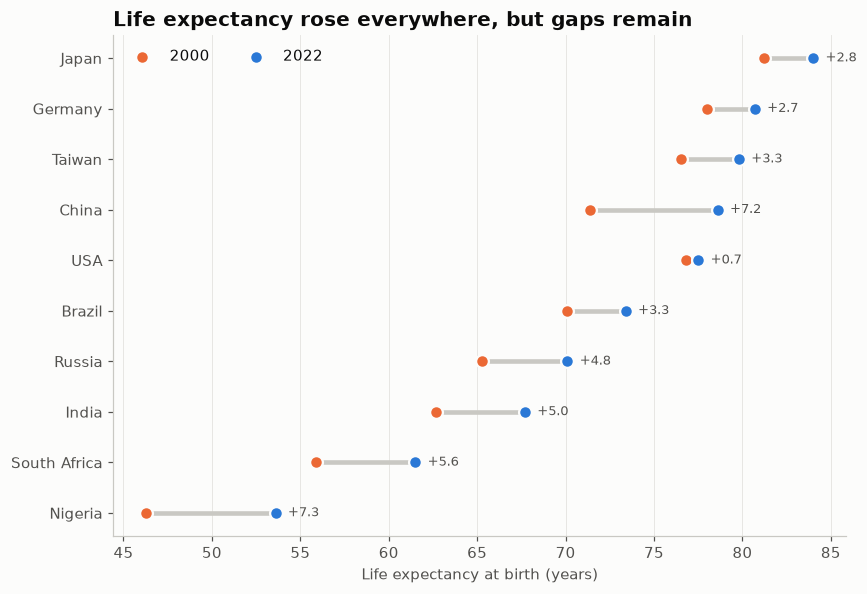

In [3]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.hlines(df.index, df[start], df[end], color="#c9c8c3", linewidth=3)
ax.scatter(df[start], df.index, color=PALETTE[1], s=70, zorder=3, label=start[1:],
           edgecolor="#fcfcfb", linewidth=1.5)
ax.scatter(df[end], df.index, color=PALETTE[0], s=70, zorder=3, label=end[1:],
           edgecolor="#fcfcfb", linewidth=1.5)
for i, r in df.iterrows():
    ax.text(max(r[start], r[end]) + 0.7, i, f"{r['gain']:+.1f}", va="center", fontsize=8.5, color="#52514e")
ax.set_yticks(df.index, df["country"])
ax.set_xlabel("Life expectancy at birth (years)")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper left", ncol=2)
ax.set_title(title)
fig.tight_layout()
plt.show()

## The same chart in other libraries

Each version uses the example data above. Pick the library that fits your stack: matplotlib/seaborn for static and print figures, plotly for interactive HTML, Altair for concise declarative specs.

### plotly

In [4]:
import plotly.graph_objects as go
fig = go.Figure()
for _, r in df.iterrows():
    fig.add_trace(go.Scatter(x=[r[start], r[end]], y=[r["country"]] * 2, mode="lines",
                             line=dict(color="#c9c8c3", width=3), showlegend=False, hoverinfo="skip"))
fig.add_trace(go.Scatter(x=df[start], y=df["country"], mode="markers", name=start[1:],
                         marker=dict(color=PALETTE[1], size=11, line=dict(color="#fcfcfb", width=1.5))))
fig.add_trace(go.Scatter(x=df[end], y=df["country"], mode="markers", name=end[1:],
                         marker=dict(color=PALETTE[0], size=11, line=dict(color="#fcfcfb", width=1.5))))
fig.update_layout(title=title, xaxis_title="Life expectancy at birth (years)", height=480,
                  legend=dict(orientation="h", y=1.08, x=0))
fig.show()

## Try it with real data

**Source:** plotly.express.data.gapminder() — Gapminder life expectancy, GDP and population 1952–2007, bundled with plotly

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [5]:
import plotly.express as px
countries = ["Japan", "Taiwan", "Germany", "United States", "China", "Brazil",
             "India", "Bangladesh", "South Africa", "Zimbabwe"]
gm = px.data.gapminder().query("year in [1982, 2007] and country in @countries")
df = (gm.pivot(index="country", columns="year", values="lifeExp")
        .rename(columns=lambda yr: f"y{yr}").rename_axis(columns=None).reset_index())
start, end = "y1982", "y2007"
title = "Life expectancy 1982 → 2007: most gained, southern Africa fell back"
df["gain"] = df[end] - df[start]
df = df.sort_values(end).reset_index(drop=True)
df

,country,y1982,y2007,gain
0,Zimbabwe,60.363,43.487,-16.876
1,South Africa,58.161,49.339,-8.822
2,Bangladesh,50.009,64.062,14.053
3,India,56.596,64.698,8.102
4,Brazil,63.336,72.390,9.054
5,China,65.525,72.961,7.436
6,United States,74.650,78.242,3.592
7,Taiwan,72.160,78.400,6.240
8,Germany,73.800,79.406,5.606
9,Japan,77.110,82.603,5.493


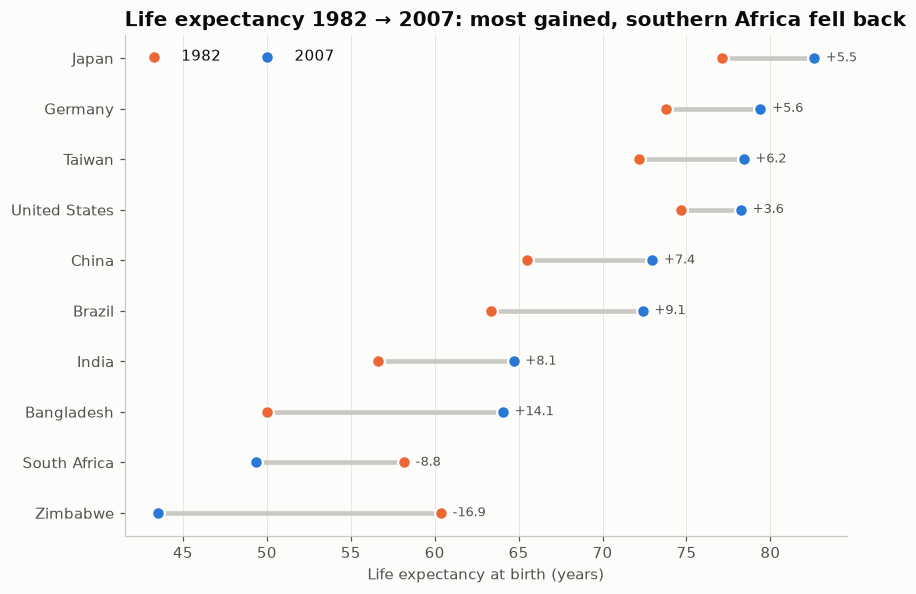

In [6]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.hlines(df.index, df[start], df[end], color="#c9c8c3", linewidth=3)
ax.scatter(df[start], df.index, color=PALETTE[1], s=70, zorder=3, label=start[1:],
           edgecolor="#fcfcfb", linewidth=1.5)
ax.scatter(df[end], df.index, color=PALETTE[0], s=70, zorder=3, label=end[1:],
           edgecolor="#fcfcfb", linewidth=1.5)
for i, r in df.iterrows():
    ax.text(max(r[start], r[end]) + 0.7, i, f"{r['gain']:+.1f}", va="center", fontsize=8.5, color="#52514e")
ax.set_yticks(df.index, df["country"])
ax.set_xlabel("Life expectancy at birth (years)")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper left", ncol=2)
ax.set_title(title)
fig.tight_layout()
plt.show()

---
Standalone script: [`dumbbell.py`](dumbbell.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)